# Projeto de classificação usando o dataset de hype de lançamento do jogo GTA VI

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [43]:
data = pd.read_csv('../datasets/gta6_fan_expectations_2026.csv',delimiter=',' )

#correlacao = data.corr(numeric_only= True)["hype_score_1to10"].sort_values(ascending=False)

#print(correlacao)
#print(data['overall_sentiment'].unique())
# data.info();


## Distribuição das features numéricas com t-SNE

Cada ponto representa um respondente; a cor indica o target `hype_score_1to10` (1 a 10). O target não entra no cálculo da projeção: usamos apenas as demais features numéricas, com valores ausentes preenchidos pela mediana e padronização. As features categóricas não são incluídas nesta visualização.

O t-SNE é uma visualização exploratória, não um classificador: os eixos não correspondem às features originais e os agrupamentos não comprovam separação das classes.

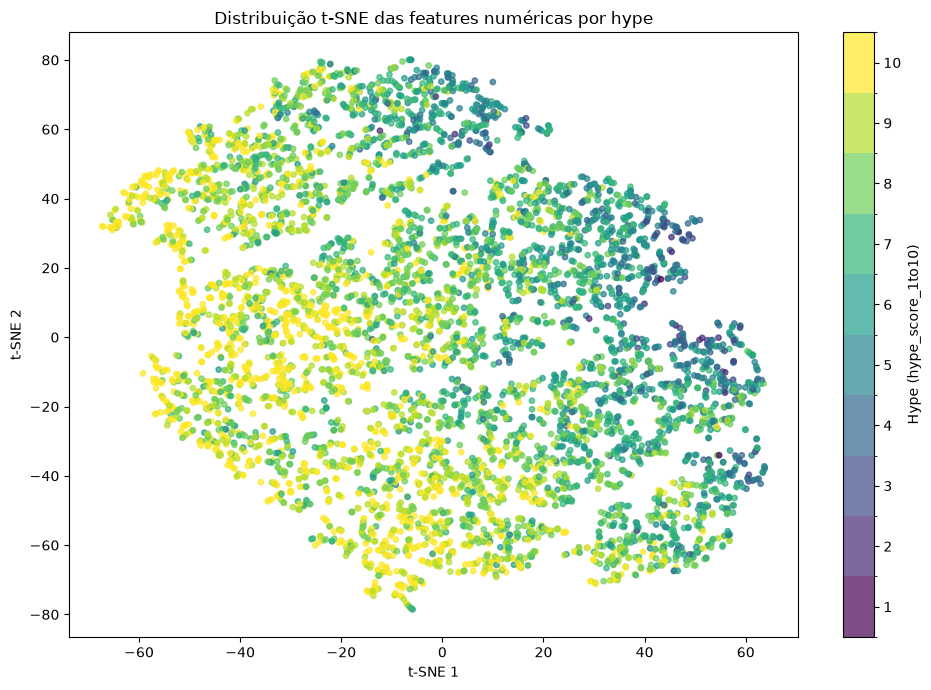

In [44]:
from sklearn.manifold import TSNE
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from matplotlib.colors import BoundaryNorm

target = "hype_score_1to10"
dados_validos = data.loc[data[target].notna()]
# O target é usado somente nas cores, nunca como entrada do t-SNE.
features_numericas = dados_validos.drop(columns=[target]).select_dtypes(include="number")
hype_scores = dados_validos[target]

if len(features_numericas) < 2:
    raise ValueError("O t-SNE precisa de pelo menos duas linhas válidas.")
if features_numericas.shape[1] == 0:
    raise ValueError("Não há features numéricas disponíveis para o t-SNE.")

perplexity = min(30, len(features_numericas) - 1)
dados_imputados = SimpleImputer(strategy="median").fit_transform(features_numericas)
dados_padronizados = StandardScaler().fit_transform(dados_imputados)
coordenadas_tsne = TSNE(
    n_components=2,
    perplexity=perplexity,
    init="random",
    learning_rate="auto",
    random_state=42,
).fit_transform(dados_padronizados)

tsne_data = pd.DataFrame(
    coordenadas_tsne, columns=["TSNE1", "TSNE2"], index=features_numericas.index
)
tsne_data[target] = hype_scores

fig, ax = plt.subplots(figsize=(10, 7))
cmap = plt.get_cmap("viridis", 10)
norm = BoundaryNorm(np.arange(0.5, 11.5), cmap.N)
pontos = ax.scatter(
    tsne_data["TSNE1"], tsne_data["TSNE2"],
    c=tsne_data[target], cmap=cmap, norm=norm, s=15, alpha=0.7,
)
barra_cores = fig.colorbar(pontos, ax=ax, ticks=range(1, 11))
barra_cores.set_label("Hype (hype_score_1to10)")

ax.set_title("Distribuição t-SNE das features numéricas por hype")
ax.set_xlabel("t-SNE 1")
ax.set_ylabel("t-SNE 2")
plt.tight_layout()
plt.show()

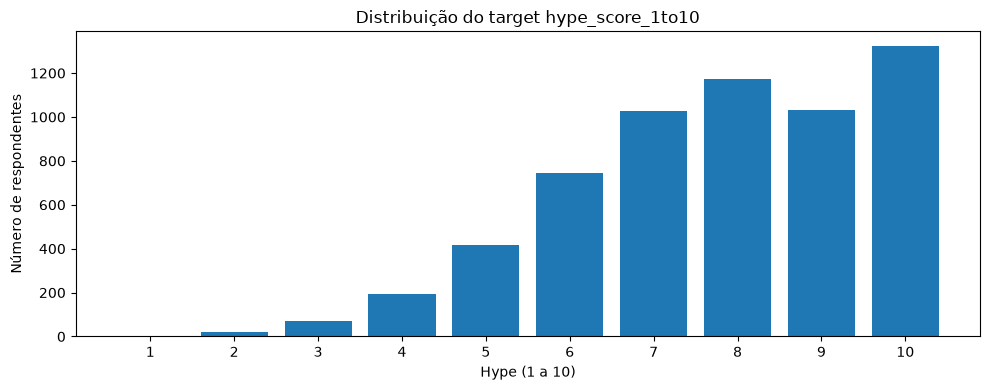

In [45]:
# Frequência de cada valor do target, para complementar a projeção.
distribuicao_hype = data["hype_score_1to10"].value_counts().reindex(range(1, 11), fill_value=0)
fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(distribuicao_hype.index, distribuicao_hype.values)
ax.set_title("Distribuição do target hype_score_1to10")
ax.set_xlabel("Hype (1 a 10)")
ax.set_ylabel("Número de respondentes")
ax.set_xticks(range(1, 11))
plt.tight_layout()
plt.show()

# Implementação da separação dos dados de teste

In [46]:
# Params
# X: array with all instances without label feature
# Y : array with all instance labels
# proportions: proportion of size, default 0.8 to train, 0.2 to test
# random_seed; seed to reproduce test data againt in future deault
def separarTreinoTeste(X, Y, proportion = 0.8, random_seed = 42):
    rng = np.random.default_rng(random_seed)
    scaler = StandardScaler()

    n = len(X)
    n_treino = int(n * proportion)

    indices = np.arange(n)
    rng.shuffle(indices)

    indices_treino = indices[:n_treino]
    indices_teste = indices[n_treino:]

    X_treino = X.iloc[indices_treino]
    X_teste = X.iloc[indices_teste]
    Y_treino = Y.iloc[indices_treino]
    Y_teste = Y.iloc[indices_teste]

    X_treino = scaler.fit_transform(X_treino)
    X_teste = scaler.fit_transform(X_teste)

    return X_treino, X_teste, Y_treino, Y_teste

# Implementação usando a biblioteca para comparar o desempenho da implementação altoral e da implementação da lib

In [47]:
from sklearn import tree

PROPORTION = 0.8
RNG_SEED = 42

y = data['hype_score_1to10']
x = data.drop('hype_score_1to10', axis= 1)


X_treino, X_teste, Y_treino, Y_teste = separarTreinoTeste(x, y, PROPORTION, RNG_SEED )

model = tree.DecisionTreeClassifier()

model.fit(X_treino, Y_treino)

p1 = model.predict(X_teste[1])

print('predito ${p1}; real: {Y_teste[1]}')


ValueError: could not convert string to float: 'R104959'